<a href="https://colab.research.google.com/github/Jovinjo/Healthcare-NoShow-Appointment/blob/main/Data_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
import pandas as pd # for data preprocessing
import numpy as np # for linear algebra
import matplotlib.pyplot as plt # for data visualization
import seaborn as sns # for data visualization
import os
import matplotlib.pyplot as plt


# Load Data and First Look Data Structure

In [8]:
path_df = "/content/drive/MyDrive/Colab Notebooks/Project 1 (No-Show-Appointment)/KaggleV2-May-2016 (1).csv"
df = pd.read_csv(path_df)
df.head() # df.tail()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [28]:
df.shape

(110527, 14)

In [52]:
df.columns.tolist()

['PatientId',
 'AppointmentID',
 'Gender',
 'ScheduledDay',
 'AppointmentDay',
 'Age',
 'Neighbourhood',
 'Scholarship',
 'Hipertension',
 'Diabetes',
 'Alcoholism',
 'Handcap',
 'SMS_received',
 'No-show']

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


# Data Quality Checks - Identify data problems before analyzing relationship / EDA

In [23]:
df.describe()

,PatientId,AppointmentID,Age,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received
count,1.105270e+05,1.105270e+05,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000,110527.000000
mean,1.474963e+14,5.675305e+06,37.088874,0.098266,0.197246,0.071865,0.030400,0.022248,0.321026
std,2.560949e+14,7.129575e+04,23.110205,0.297675,0.397921,0.258265,0.171686,0.161543,0.466873
min,3.921784e+04,5.030230e+06,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.172614e+12,5.640286e+06,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.173184e+13,5.680573e+06,37.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.439172e+13,5.725524e+06,55.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,9.999816e+14,5.790484e+06,115.000000,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000


In [35]:
df.dtypes

,0
PatientId,float64
AppointmentID,int64
Gender,object
ScheduledDay,object
AppointmentDay,object
Age,int64
Neighbourhood,object
Scholarship,int64
Hipertension,int64
Diabetes,int64


In [53]:
# 1. Missing values
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": df.isna().mean() * 100
})
display(missing)

,Missing Count,Missing %
PatientId,0,0.0
AppointmentID,0,0.0
Gender,0,0.0
ScheduledDay,0,0.0
AppointmentDay,0,0.0
Age,0,0.0
Neighbourhood,0,0.0
Scholarship,0,0.0
Hipertension,0,0.0
Diabetes,0,0.0


In [37]:
df.duplicated().sum()

np.int64(0)

In [55]:
df.nunique()

,0
PatientId,62299
AppointmentID,110527
Gender,2
ScheduledDay,103549
AppointmentDay,27
Age,104
Neighbourhood,81
Scholarship,2
Hipertension,2
Diabetes,2


In [56]:
print('Values in Gender:', df.Gender.unique())
print('Values in Neighbourhood:',df.Neighbourhood.unique())
print('Values in Scholarship:',df.Scholarship.unique())
print('Values in Hypertension:',df.Hipertension.unique())
print('Values in Diabetes:',df.Diabetes.unique())
print('Values in Alcoholism:',df.Alcoholism.unique())
print('Values in Handicap:',df.Handcap.unique())
print('Values in SMS_received:',df.SMS_received.unique())
print('Values in No_Show:', df['No-show'].unique())

Values in Gender: ['F' 'M']
Values in Neighbourhood: ['JARDIM DA PENHA' 'MATA DA PRAIA' 'PONTAL DE CAMBURI' 'REPÚBLICA'
 'GOIABEIRAS' 'ANDORINHAS' 'CONQUISTA' 'NOVA PALESTINA' 'DA PENHA'
 'TABUAZEIRO' 'BENTO FERREIRA' 'SÃO PEDRO' 'SANTA MARTHA' 'SÃO CRISTÓVÃO'
 'MARUÍPE' 'GRANDE VITÓRIA' 'SÃO BENEDITO' 'ILHA DAS CAIEIRAS'
 'SANTO ANDRÉ' 'SOLON BORGES' 'BONFIM' 'JARDIM CAMBURI' 'MARIA ORTIZ'
 'JABOUR' 'ANTÔNIO HONÓRIO' 'RESISTÊNCIA' 'ILHA DE SANTA MARIA'
 'JUCUTUQUARA' 'MONTE BELO' 'MÁRIO CYPRESTE' 'SANTO ANTÔNIO' 'BELA VISTA'
 'PRAIA DO SUÁ' 'SANTA HELENA' 'ITARARÉ' 'INHANGUETÁ' 'UNIVERSITÁRIO'
 'SÃO JOSÉ' 'REDENÇÃO' 'SANTA CLARA' 'CENTRO' 'PARQUE MOSCOSO'
 'DO MOSCOSO' 'SANTOS DUMONT' 'CARATOÍRA' 'ARIOVALDO FAVALESSA'
 'ILHA DO FRADE' 'GURIGICA' 'JOANA D´ARC' 'CONSOLAÇÃO' 'PRAIA DO CANTO'
 'BOA VISTA' 'MORADA DE CAMBURI' 'SANTA LUÍZA' 'SANTA LÚCIA'
 'BARRO VERMELHO' 'ESTRELINHA' 'FORTE SÃO JOÃO' 'FONTE GRANDE'
 'ENSEADA DO SUÁ' 'SANTOS REIS' 'PIEDADE' 'JESUS DE NAZARETH'
 'SANTA TEREZ

In [58]:
df["Handcap"].value_counts()

,count
Handcap,
0,108286
1,2042
2,183
3,13
4,3


In [47]:
# 5. Categorical values
cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    print(f"\n")
    print(df[col].value_counts(dropna=False).head(5))



Gender
F    71840
M    38687
Name: count, dtype: int64


ScheduledDay
2016-05-06T07:09:54Z    24
2016-05-06T07:09:53Z    23
2016-04-25T17:18:27Z    22
2016-04-25T17:17:46Z    22
2016-04-25T17:17:23Z    19
Name: count, dtype: int64


AppointmentDay
2016-06-06T00:00:00Z    4692
2016-05-16T00:00:00Z    4613
2016-05-09T00:00:00Z    4520
2016-05-30T00:00:00Z    4514
2016-06-08T00:00:00Z    4479
Name: count, dtype: int64


Neighbourhood
JARDIM CAMBURI     7717
MARIA ORTIZ        5805
RESISTÊNCIA        4431
JARDIM DA PENHA    3877
ITARARÉ            3514
Name: count, dtype: int64


No-show
No     88208
Yes    22319
Name: count, dtype: int64


In [50]:
df[df["Age"]<0]

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
99832,4.659432e+14,5775010,F,2016-06-06T08:58:13Z,2016-06-06T00:00:00Z,-1,ROMÃO,0,0,0,0,0,0,No


Problems Discovered:
1. Renaming - Hipertension, Handcap, No-show
2. Age is -1 need to be removed, also check what about age max 115.
3. Handicap level 0-4 are right. look at Google.
4. Object conversion - PatientID(float to int to string),ScheduledDay(object to Datetime), AppointmentDay(object to Date), Gender(object to category), Neighbourhood(object to category), AppointmentID(int to string)
5. Flip No-Show to Showed_Up - values also flipped
6. Create ScheduleDayOnly, Remove time 00.00.00 from AppointmentDay
7. Create DaysUntilAppointment = AppointmentDay - ScheduledDayOnly
8. Create AppointmentMonth, AppointmentDayOfWeek

Additional Category/Object conversion for ML:
1. Gender, Neighbourhood (nominal category/no natural order) - encoded with one-hot encoding
2. 1,0 type will stay as it is

# Data Cleaning

In [65]:
# Renaming
df.rename(columns = {"Hipertension":"Hypertension","Handcap":"Handicap","No_Show":"Showed_Up"},inplace=True)
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,Showed_Up
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [76]:
# Remove Age -1
df = df[(df["Age"]>=0)]

In [101]:
# Datatype conversion
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'],errors='coerce') #coerce tells to return NaN when erro
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'],errors='coerce')
df['PatientId'] = df['PatientId'].astype(int).astype(str)
df['AppointmentID'] = df['AppointmentID'].astype(str)
df['Gender'] = df['Gender'].astype('category')
df['Neighbourhood'] = df['Neighbourhood'].astype('category')
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay']).dt.date.astype('datetime64[ns]')

# Flip values Showed_Up
df['Showed_Up'] = df['Showed_Up'].map({'Yes': 0, 'No': 1}).astype(int)

# Additional column
df['ScheduledDayOnly'] = df['ScheduledDay'].dt.date.astype('datetime64[ns]')
df['DaysUntilAppointment'] = (df['AppointmentDay'] - df['ScheduledDayOnly']).dt.days
df['AppointmentMonth'] = df['AppointmentDay'].dt.month
df['AppointmentDayOfWeek'] = df['AppointmentDay'].dt.dayofweek
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,Showed_Up,DaysUntilAppointment,AppointmentMonth,AppointmentDayOfWeek,ScheduleDayOnly,ScheduledDayOnly
0,29872499824296,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29,62,JARDIM DA PENHA,0,1,0,0,0,0,1,0,4,4,2016-04-29,2016-04-29
1,558997776694438,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29,56,JARDIM DA PENHA,0,0,0,0,0,0,1,0,4,4,2016-04-29,2016-04-29
2,4262962299951,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29,62,MATA DA PRAIA,0,0,0,0,0,0,1,0,4,4,2016-04-29,2016-04-29
3,867951213174,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29,8,PONTAL DE CAMBURI,0,0,0,0,0,0,1,0,4,4,2016-04-29,2016-04-29
4,8841186448183,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29,56,JARDIM DA PENHA,0,1,1,0,0,0,1,0,4,4,2016-04-29,2016-04-29


In [110]:
df[df["DaysUntilAppointment"]<0] # Need to be reviewed and decided what to do with <0

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,Showed_Up,DaysUntilAppointment,AppointmentMonth,AppointmentDayOfWeek,ScheduledDayOnly
27033,7839272661752,5679978,M,2016-05-10 10:51:53+00:00,2016-05-09,38,RESISTÊNCIA,0,0,0,0,1,0,0,-1,5,0,2016-05-10
55226,7896293967868,5715660,F,2016-05-18 14:50:41+00:00,2016-05-17,19,SANTO ANTÔNIO,0,0,0,0,1,0,0,-1,5,1,2016-05-18
64175,24252258389979,5664962,F,2016-05-05 13:43:58+00:00,2016-05-04,22,CONSOLAÇÃO,0,0,0,0,0,0,0,-1,5,2,2016-05-05
71533,998231581612122,5686628,F,2016-05-11 13:49:20+00:00,2016-05-05,81,SANTO ANTÔNIO,0,0,0,0,0,0,0,-6,5,3,2016-05-11
72362,3787481966821,5655637,M,2016-05-04 06:50:57+00:00,2016-05-03,7,TABUAZEIRO,0,0,0,0,0,0,0,-1,5,1,2016-05-04


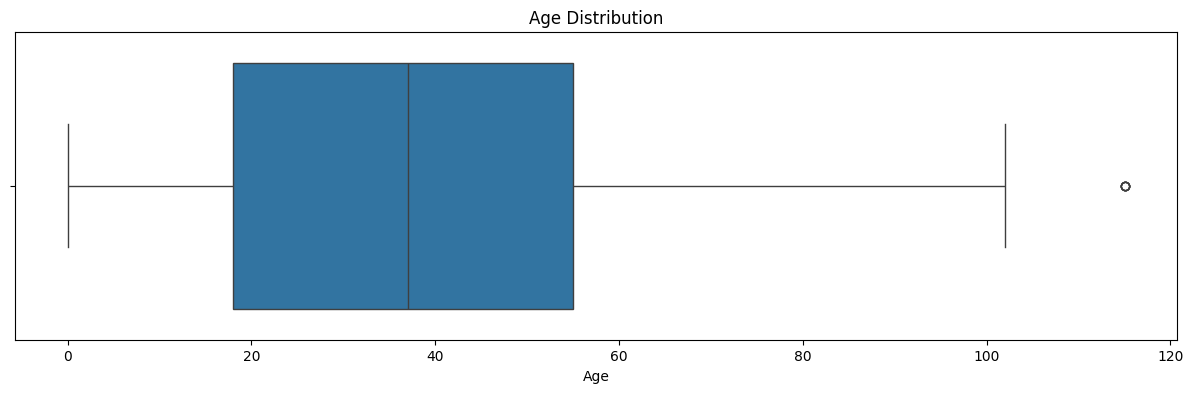

In [94]:
plt.figure(figsize=(15,4))
dist_age=sns.boxplot(x='Age',data=df)
plt.title('Age Distribution')
plt.show() # Need to be reviewed and decide what to do with Age > 110

In [96]:
df[df["Age"]==0].head() # Need to be reviewed and decide what to do with Age==0

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_received,Showed_Up,DaysUntilAppointment,AppointmentMonth,AppointmentDayOfWeek
59,71844284745331,5638545,F,2016-04-29 08:08:43+00:00,2016-04-29 00:00:00+00:00,0,CONQUISTA,0,0,0,0,0,0,1,-1,4,4
63,236623344873175,5628286,M,2016-04-27 10:46:12+00:00,2016-04-29 00:00:00+00:00,0,SÃO BENEDITO,0,0,0,0,0,0,1,1,4,4
64,188517384712787,5616082,M,2016-04-25 13:28:21+00:00,2016-04-29 00:00:00+00:00,0,ILHA DAS CAIEIRAS,0,0,0,0,0,1,1,3,4,4
65,271881817799985,5628321,M,2016-04-27 10:48:50+00:00,2016-04-29 00:00:00+00:00,0,CONQUISTA,0,0,0,0,0,0,1,1,4,4
67,86471282513499,5639264,F,2016-04-29 08:53:02+00:00,2016-04-29 00:00:00+00:00,0,NOVA PALESTINA,0,0,0,0,0,0,1,-1,4,4


Need further investigation and decision:
1. DaysuntilAppointment < 0
2. Age outlier > 110
3. Age == 0

# Exploratory Data Analysis (EDA)